In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    log_loss
)

import warnings
warnings.filterwarnings("ignore")

print("Logistic Regression Environment Ready!")

Logistic Regression Environment Ready!


In [2]:
# Sample dataset
data = {
    "Study_Hours": [
        1, 2, 2.5, 3, 3.5,
        4, 4.5, 5, 5.5, 6,
        6.5, 7, 7.5, 8, 9,
        10, 2.2, 3.2, 5.2, 8.5
    ],
    "Pass": [
        0, 0, 0, 0, 0,
        0, 0, 1, 1, 1,
        1, 1, 1, 1, 1,
        1, 0, 0, 1, 1
    ]
}

df = pd.DataFrame(data)

print("Dataset Created Successfully!")
print("Dataset Shape:", df.shape)

display(df.head(10))

Dataset Created Successfully!
Dataset Shape: (20, 2)


,Study_Hours,Pass
0,1.0,0
1,2.0,0
2,2.5,0
3,3.0,0
4,3.5,0
5,4.0,0
6,4.5,0
7,5.0,1
8,5.5,1
9,6.0,1


In [3]:
print("Target Class Distribution:")
display(df["Pass"].value_counts())

print("\nTarget Class Percentages:")
display(df["Pass"].value_counts(normalize=True) * 100)

Target Class Distribution:


Pass
1    11
0     9
Name: count, dtype: int64


Target Class Percentages:


Pass
1    55.0
0    45.0
Name: proportion, dtype: float64

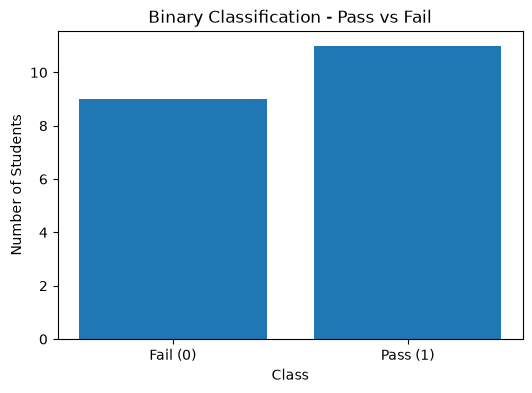

In [4]:
# Count the two classes
class_counts = df["Pass"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Fail (0)", "Pass (1)"],
    class_counts.values
)

plt.title("Binary Classification - Pass vs Fail")
plt.xlabel("Class")
plt.ylabel("Number of Students")

plt.show()

In [5]:
# Separate features and target
X = df[["Study_Hours"]]
y = df["Pass"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create and train Logistic Regression model
log_model = LogisticRegression()

log_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


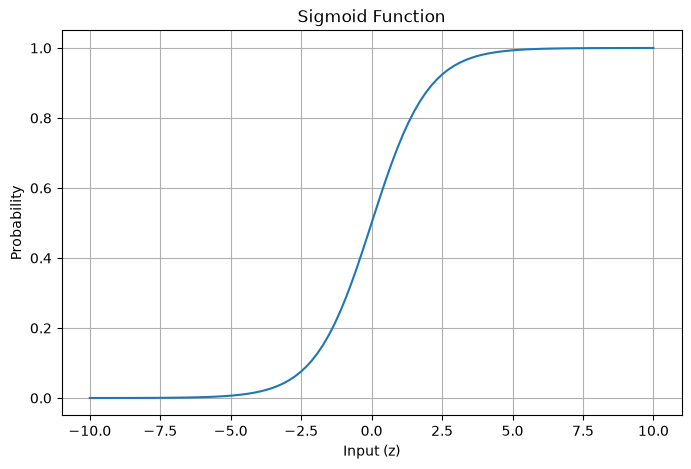

In [6]:
# Create sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Generate input values
z = np.linspace(-10, 10, 100)

# Calculate sigmoid values
sigmoid_values = sigmoid(z)

# Plot sigmoid curve
plt.figure(figsize=(8, 5))

plt.plot(z, sigmoid_values)

plt.title("Sigmoid Function")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.grid(True)

plt.show()

In [7]:
# Calculate probabilities
probabilities = log_model.predict_proba(X_test)

probability_df = pd.DataFrame({
    "Study_Hours": X_test["Study_Hours"].values,
    "Fail_Probability": probabilities[:, 0],
    "Pass_Probability": probabilities[:, 1],
    "Actual_Result": y_test.values
})

display(probability_df)

,Study_Hours,Fail_Probability,Pass_Probability,Actual_Result
0,3.0,0.895356,0.104644,0
1,6.0,0.088553,0.911447,1
2,8.0,0.004884,0.995116,1
3,4.5,0.476920,0.523080,0


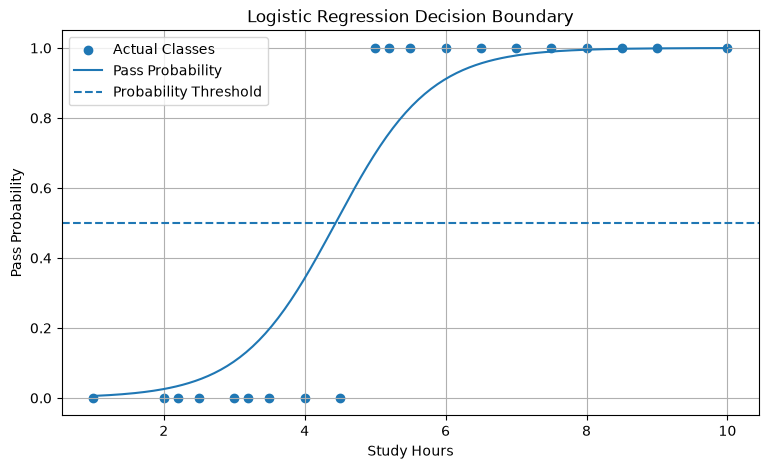

In [8]:
# Generate probability predictions
study_hours_range = np.linspace(
    df["Study_Hours"].min(),
    df["Study_Hours"].max(),
    200
).reshape(-1, 1)

probability_curve = log_model.predict_proba(
    study_hours_range
)[:, 1]

# Plot decision boundary
plt.figure(figsize=(9, 5))

plt.scatter(
    X["Study_Hours"],
    y,
    label="Actual Classes"
)

plt.plot(
    study_hours_range,
    probability_curve,
    label="Pass Probability"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Probability Threshold"
)

plt.xlabel("Study Hours")
plt.ylabel("Pass Probability")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.grid(True)

plt.show()

In [9]:
# Get probabilities for the test data
pass_probabilities = log_model.predict_proba(X_test)[:, 1]

# Apply threshold
threshold = 0.5

custom_predictions = (
    pass_probabilities >= threshold
).astype(int)

print("Predicted Classes:", custom_predictions)
print("Actual Classes:", y_test.values)

print(
    "Accuracy:",
    accuracy_score(y_test, custom_predictions)
)

Predicted Classes: [0 1 1 1]
Actual Classes: [0 1 1 0]
Accuracy: 0.75


In [10]:
# Compare different thresholds
for threshold in [0.3, 0.5, 0.7]:

    predictions = (
        pass_probabilities >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    print(
        f"Threshold: {threshold} | Accuracy: {accuracy:.2f}"
    )

Threshold: 0.3 | Accuracy: 0.75
Threshold: 0.5 | Accuracy: 0.75
Threshold: 0.7 | Accuracy: 1.00


In [11]:
# Calculate predicted probabilities
y_prob = log_model.predict_proba(X_test)

# Calculate Log Loss
loss = log_loss(y_test, y_prob)

print("Log Loss:", loss)

Log Loss: 0.23713965410590737


In [12]:
# Display model coefficients
coefficient_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_model.coef_[0]
})

display(coefficient_df)

print("Intercept:", log_model.intercept_[0])

,Feature,Coefficient
0,Study_Hours,1.492695


Intercept: -6.624743212230555


In [13]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Load Iris dataset
iris = load_iris()

X_iris = iris.data
y_iris = iris.target

# Split dataset
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris,
    y_iris,
    test_size=0.2,
    random_state=42,
    stratify=y_iris
)

# Create multiclass Logistic Regression model
multi_model = LogisticRegression(max_iter=500)

# Train model
multi_model.fit(X_train_iris, y_train_iris)

# Predict
y_pred_iris = multi_model.predict(X_test_iris)

# Evaluate
print("Multiclass Classification Accuracy:",
      accuracy_score(y_test_iris, y_pred_iris))

print("\nClassification Report:")
print(classification_report(
    y_test_iris,
    y_pred_iris,
    target_names=iris.target_names
))

Multiclass Classification Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



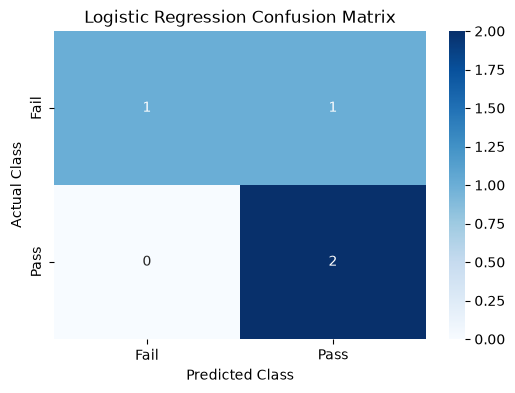

In [14]:
# Confusion matrix for student classification
y_pred = log_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

# Prepare dataset
X = df[["Study_Hours"]]
y = df["Pass"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
final_model = LogisticRegression()
final_model.fit(X_train, y_train)

# Predictions
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)

# Evaluation
print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Log Loss:", log_loss(y_test, y_prob))

# Predict a new student
new_student = pd.DataFrame({
    "Study_Hours": [7]
})

prediction = final_model.predict(new_student)
probability = final_model.predict_proba(new_student)

print("\nNew Student Prediction:")
print("Predicted Class:", prediction[0])
print("Pass Probability:", probability[0][1])

Logistic Regression Results
---------------------------
Accuracy: 0.75
Precision: 0.6666666666666666
Recall: 1.0
F1 Score: 0.8
Log Loss: 0.23713965410590737

New Student Prediction:
Predicted Class: 1
Pass Probability: 0.9786291107966336
